# 1. Vectors and Vector Spaces
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Multiplication by $z$ is a rotation through $\arg z$ combined with a scaling by $\lvert z\rvert$. Left, $z$, $w$ and their product; the angles add and the lengths multiply. Right, the powers $z^k$ of a number of modulus slightly above one spiral outward; the powers of $i$ cycle through four points.

Text(0.5, 1.0, 'powers of $q$ and of $i$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


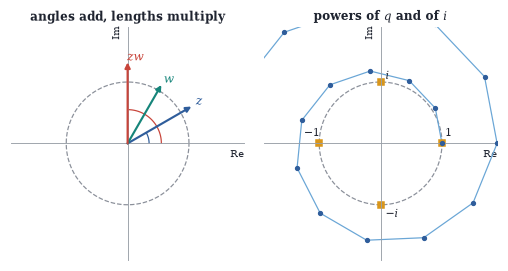

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

z, w = 1.2 * np.exp(1j * np.pi / 6), 1.1 * np.exp(1j * np.pi / 3)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.35))
ax = complex_plane(axs[0], 1.9, ticks=False)
unit_circle(ax)
for c, col, lab in [(z, BLUE, "$z$"), (w, TEAL, "$w$"), (z * w, RED, "$zw$")]:
    arrow(ax, (c.real, c.imag), color=col, label=lab, offset=(0.13, 0.08))
th = np.linspace(0, np.angle(z), 30); ax.plot(0.35*np.cos(th), 0.35*np.sin(th), color=BLUE, lw=0.8)
th = np.linspace(0, np.angle(z*w), 30); ax.plot(0.55*np.cos(th), 0.55*np.sin(th), color=RED, lw=0.8)
ax.set_title("angles add, lengths multiply")

ax = complex_plane(axs[1], 1.9, ticks=False)
unit_circle(ax)
q = 1.06 * np.exp(1j * 2 * np.pi / 11)
P = q ** np.arange(0, 22)
ax.plot(P.real, P.imag, "-", color=SKY, lw=0.8)
ax.scatter(P.real, P.imag, s=6, color=BLUE, zorder=3)
for k in range(4):
    p = 1j ** k
    ax.plot(p.real, p.imag, "s", color=GOLD, ms=4)
ax.text(1.05, 0.12, "$1$", fontsize=7); ax.text(0.08, 1.05, "$i$", fontsize=7)
ax.text(-1.25, 0.12, "$-1$", fontsize=7); ax.text(0.08, -1.2, "$-i$", fontsize=7)
ax.set_title("powers of $q$ and of $i$")

Addition and scaling in $\R^2$. Left, the parallelogram law: $x+y$ is the diagonal of the parallelogram with sides $x$ and $y$. Right, the multiples $\lambda x$ for $\lambda\in\{-1,-\tfrac12,\tfrac12,1,2\}$ all lie on one line through the origin.

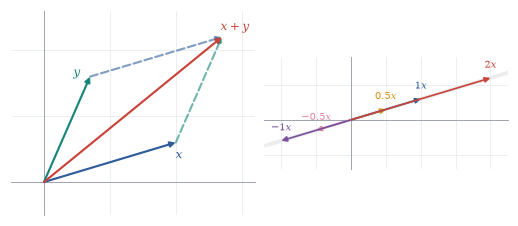

In [3]:
x, y = np.array([2.0, 0.6]), np.array([0.7, 1.6])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
ax = plane(axs[0], (-0.5, 3.2, -0.5, 2.6))
arrow(ax, x, color=BLUE, label="$x$", offset=(0.05, -0.2))
arrow(ax, y, color=TEAL, label="$y$", offset=(-0.2, 0.05))
arrow(ax, y, origin=x, color=TEAL, ls="--", alpha=0.6)
arrow(ax, x, origin=y, color=BLUE, ls="--", alpha=0.6)
arrow(ax, x + y, color=RED, label="$x+y$", offset=(0.2, 0.15))
ax = plane(axs[1], (-2.5, 4.5, -1.4, 1.8))
span_line(ax, x, lim=4, color=LIGHT, lw=2.5)
for lam, col in [(-1, PLUM), (-0.5, ROSE), (0.5, GOLD), (1, BLUE), (2, RED)]:
    arrow(ax, lam * x, color=col, lw=1.1, z=3 + abs(lam))
    ax.text(*(lam * x + np.array([0, 0.28])), rf"${lam:g}x$", fontsize=6.5, color=col, ha="center")

Multiplication tables modulo $5$ and modulo $6$, coloured by the product. Modulo the prime $5$, every nonzero row is a permutation of the nonzero residues, so every nonzero element has an inverse. Modulo $6$ the rows for $2$, $3$ and $4$ hit zero and repeat values: these elements have no inverses.

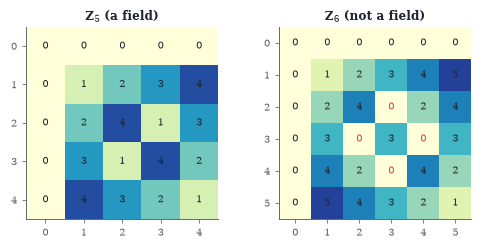

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.15))
for ax, p in zip(axs, (5, 6)):
    T = np.outer(np.arange(p), np.arange(p)) % p
    ax.imshow(T, cmap="YlGnBu", vmin=0, vmax=p)
    for (i, j), v in np.ndenumerate(T):
        ax.text(j, i, v, ha="center", va="center", fontsize=6.5,
                color=RED if (v == 0 and i and j) else INK)
    ax.set_xticks(range(p)); ax.set_yticks(range(p))
    ax.set_title(rf"$\mathbf{{Z}}_{p}$" + (" (a field)" if p == 5 else " (not a field)"))

Functions on $[0,1]$ are vectors. The sum $f+g$ is computed pointwise, as is the scalar multiple $-\tfrac12 f$. The zero vector of this space is the constant function $0$, drawn as the horizontal axis.

(0.0, 1.0)

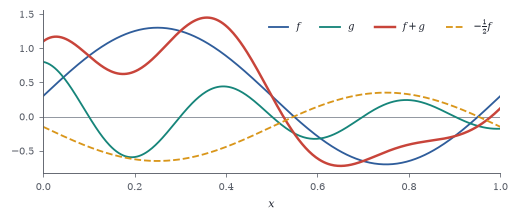

In [5]:
t = np.linspace(0, 1, 400)
f = np.sin(2 * np.pi * t) + 0.3
g = 0.8 * np.cos(5 * np.pi * t) * np.exp(-1.5 * t)
fig, ax = plt.subplots(figsize=(W, 1.9))
ax.axhline(0, color=GRAY, lw=0.6)
ax.plot(t, f, color=BLUE, label="$f$")
ax.plot(t, g, color=TEAL, label="$g$")
ax.plot(t, f + g, color=RED, lw=1.6, label="$f+g$")
ax.plot(t, -0.5 * f, color=GOLD, ls="--", label=r"$-\frac{1}{2}f$")
ax.legend(ncol=4, loc="upper right"); ax.set_xlabel("$x$"); ax.set_xlim(0, 1)

The positive reals with $x\oplus y=xy$ and $\lambda\odot x=x^\lambda$ form a real vector space. The logarithm carries it onto the ordinary real line, sending $\oplus$ to $+$ and $\odot$ to ordinary multiplication; equally spaced points on the right correspond to geometrically spaced points on the left.

Text(0.5, 1.0, 'after $\\log$: $(\\mathbf{R},+,\\cdot)$')

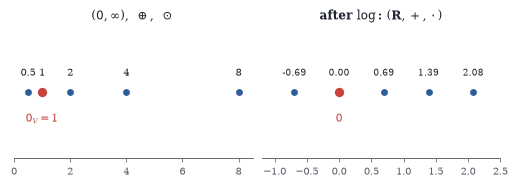

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(W, 1.6))
xs = 2.0 ** np.arange(-1, 4)
for ax in axs:
    ax.spines["left"].set_visible(False); ax.set_yticks([])
ax = axs[0]
ax.scatter(xs, 0 * xs, color=BLUE, s=12, zorder=3)
for x in xs:
    ax.text(x, 0.25, f"{x:g}", ha="center", fontsize=6.5)
ax.scatter([1], [0], color=RED, s=26, zorder=4); ax.text(1, -0.45, r"$0_V=1$", color=RED, ha="center", fontsize=7)
ax.set_xlim(0, 8.5); ax.set_ylim(-1, 1); ax.set_title(r"$(0,\infty),\ \oplus,\ \odot$")
ax = axs[1]
ls = np.log(xs)
ax.scatter(ls, 0 * ls, color=BLUE, s=12, zorder=3)
for x, l in zip(xs, ls):
    ax.text(l, 0.25, f"{l:.2f}", ha="center", fontsize=6)
ax.scatter([0], [0], color=RED, s=26, zorder=4); ax.text(0, -0.45, "$0$", color=RED, ha="center", fontsize=7)
ax.set_xlim(-1.2, 2.5); ax.set_ylim(-1, 1); ax.set_title(r"after $\log$: $(\mathbf{R},+,\cdot)$")

In [7]:
# Check the eight axioms numerically for the exotic space above.
rng = np.random.default_rng(0)
add  = lambda x, y: x * y
smul = lambda a, x: x ** a
x, y, z = rng.uniform(0.1, 5, 3); a, b = rng.normal(size=2)
checks = {
    "commutativity": add(x, y) - add(y, x),
    "assoc (+)": add(add(x, y), z) - add(x, add(y, z)),
    "assoc (scalars)": smul(a * b, x) - smul(a, smul(b, x)),
    "identity 0_V = 1": add(x, 1.0) - x,
    "inverse 1/x": add(x, 1 / x) - 1.0,
    "1 * x = x": smul(1.0, x) - x,
    "a(x+y) = ax+ay": smul(a, add(x, y)) - add(smul(a, x), smul(a, y)),
    "(a+b)x = ax+bx": smul(a + b, x) - add(smul(a, x), smul(b, x)),
}
for k, v in checks.items():
    print(f"{k:18s} residual {v: .1e}")

commutativity      residual  0.0e+00
assoc (+)          residual  2.2e-16
assoc (scalars)    residual  0.0e+00
identity 0_V = 1   residual  0.0e+00
inverse 1/x        residual  0.0e+00
1 * x = x          residual  0.0e+00
a(x+y) = ax+ay     residual  0.0e+00
(a+b)x = ax+bx     residual -1.1e-16


In $\R^3$, the plane $x_1+2x_2+3x_3=0$ (blue) and the line spanned by $(1,1,-1)$ (red) are subspaces. The parallel plane $x_1+2x_2+3x_3=4$ (gold) is not: it misses the origin, and the sum of two of its points (the arrows) lands on a different parallel plane.

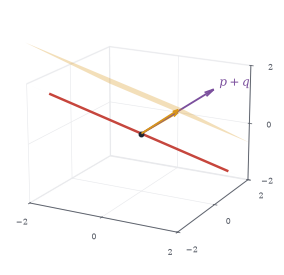

In [8]:
fig = plt.figure(figsize=(W * 0.62, W * 0.52))
ax = ax3d(fig, elev=18, azim=-62, lim=2)
plane3d(ax, (1, 2, 3), 0, lim=2, color=SKY, alpha=0.35)
plane3d(ax, (1, 2, 3), 4, lim=2, color=GOLD, alpha=0.30)
t = np.linspace(-1.6, 1.6, 2)
ax.plot(t, t, -t, color=RED, lw=1.6)
p, q = np.array([1.0, 0.0, 1.0]), np.array([0.0, 2.0, 0.0])
arrow3d(ax, p, color=GOLD, lw=1.2); arrow3d(ax, q, color=GOLD, lw=1.2)
arrow3d(ax, p + q, color=PLUM, lw=1.2, label="$p+q$")
ax.scatter([0], [0], [0], color=INK, s=8)
ax.set_xticks([-2, 0, 2]); ax.set_yticks([-2, 0, 2]); ax.set_zticks([-2, 0, 2])

The sum of two lines $U$ and $W$ through the origin in $\R^3$ is the plane they span. A typical element $u+w$ (purple) is reached by walking along $U$ and then along $W$; the union $U\cup W$, by contrast, is just the two lines.

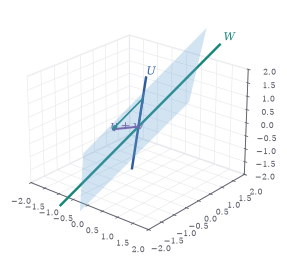

In [9]:
fig = plt.figure(figsize=(W * 0.6, W * 0.5))
ax = ax3d(fig, elev=24, azim=-50, lim=2)
u, w = np.array([1.0, -1.0, 2.0]) / 1.5, np.array([1.0, 1.0, 2.0]) / 1.5
n = np.cross(u, w)
s, r = np.meshgrid(np.linspace(-1.6, 1.6, 2), np.linspace(-1.6, 1.6, 2))
P = s[..., None] * u + r[..., None] * w
ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=SKY, alpha=0.3, lw=0, shade=False)
t = np.array([-2.2, 2.2])
ax.plot(t * u[0], t * u[1], t * u[2], color=BLUE, lw=1.6); ax.text(*(2.3 * u), "$U$", color=BLUE)
ax.plot(t * w[0], t * w[1], t * w[2], color=TEAL, lw=1.6); ax.text(*(2.3 * w), "$W$", color=TEAL)
a, b = 1.3, -0.8
arrow3d(ax, a * u, color=BLUE, lw=1.1)
arrow3d(ax, b * w, origin=a * u, color=TEAL, lw=1.1)
arrow3d(ax, a * u + b * w, color=PLUM, lw=1.3, label="$u+w$")

In [10]:
# U = {(x, -x, 2x)}, W = {(x, x, 2x)}.  Which vectors of R^3 are in U + W?
u, w = np.array([1, -1, 2.0]), np.array([1, 1, 2.0])
M = np.column_stack([u, w])
for v in [np.array([3.0, 1.0, 6.0]), np.array([0.0, 0.0, 1.0])]:
    coef, res, *_ = np.linalg.lstsq(M, v, rcond=None)
    print(v, "in U+W" if np.allclose(M @ coef, v) else "not in U+W",
          " coefficients:", coef.round(3))
# U + W is a plane through 0; its normal vector is the cross product u x w
print("normal to U+W:", np.cross(u, w))

[3. 1. 6.] in U+W  coefficients: [1. 2.]
[0. 0. 1.] not in U+W  coefficients: [0.2 0.2]
normal to U+W: [-4.  0.  2.]


Direct and non-direct sums in $\R^2$. Left, with two lines $V_1$ and $V_2$ meeting only at $0$, every vector $v$ has exactly one decomposition $v=v_1+v_2$. Right, with three lines, the same $v$ has infinitely many decompositions; two are shown, and their difference is a nontrivial way of writing $0$.

Text(0.5, 1.0, '$V_1+V_2+V_3$: not direct')

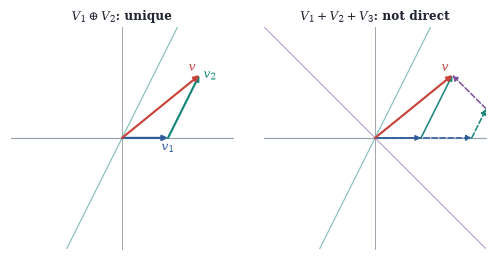

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.25))
d1, d2, d3 = np.array([1.0, 0.0]), np.array([0.5, 1.0]), np.array([-1.0, 1.0])
v = np.array([1.6, 1.3])
ax = plane(axs[0], 2.3, grid=False)
for d, col, nm in [(d1, BLUE, "$V_1$"), (d2, TEAL, "$V_2$")]:
    span_line(ax, d, lim=3, color=col, lw=0.8, alpha=0.5)
c = np.linalg.solve(np.column_stack([d1, d2]), v)
arrow(ax, c[0] * d1, color=BLUE, label="$v_1$", offset=(0, -0.2))
arrow(ax, c[1] * d2, origin=c[0] * d1, color=TEAL, label="$v_2$", offset=(0.22, 0))
arrow(ax, v, color=RED, label="$v$", offset=(-0.15, 0.15))
ax.set_title(r"$V_1\oplus V_2$: unique")
ax = plane(axs[1], 2.3, grid=False)
for d, col in [(d1, BLUE), (d2, TEAL), (d3, PLUM)]:
    span_line(ax, d, lim=3, color=col, lw=0.8, alpha=0.5)
for s, ls in [(0.0, "-"), (0.7, "--")]:
    # v = a d1 + b d2 + s d3 ; solve for a, b given s
    a, b = np.linalg.solve(np.column_stack([d1, d2]), v - s * d3)
    p0 = np.zeros(2); p1 = a * d1; p2 = p1 + b * d2
    arrow(ax, p1 - p0, color=BLUE, ls=ls, lw=1.0)
    arrow(ax, b * d2, origin=p1, color=TEAL, ls=ls, lw=1.0)
    if s: arrow(ax, s * d3, origin=p2, color=PLUM, ls=ls, lw=1.0)
arrow(ax, v, color=RED, label="$v$", offset=(-0.15, 0.15))
ax.set_title(r"$V_1+V_2+V_3$: not direct")

The decomposition of $f(x)=e^{x}\,(1+0.4\sin 3x)$ into its even part (symmetric about the vertical axis) and its odd part (symmetric about the origin). The two parts add back to $f$, and the decomposition is unique because only the zero function is both even and odd.

(-2.0, 2.0)

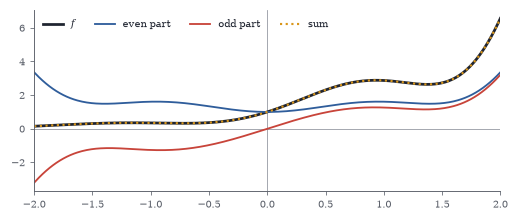

In [12]:
x = np.linspace(-2, 2, 400)
f = lambda x: np.exp(x) * (1 + 0.4 * np.sin(3 * x))
fe, fo = (f(x) + f(-x)) / 2, (f(x) - f(-x)) / 2
fig, ax = plt.subplots(figsize=(W, 1.9))
ax.axhline(0, color=GRAY, lw=0.5); ax.axvline(0, color=GRAY, lw=0.5)
ax.plot(x, f(x), color=INK, lw=1.8, label="$f$")
ax.plot(x, fe, color=BLUE, label="even part")
ax.plot(x, fo, color=RED, label="odd part")
ax.plot(x, fe + fo, color=GOLD, ls=":", lw=1.4, label="sum")
ax.legend(ncol=4, loc="upper left"); ax.set_xlim(-2, 2)

Roots of unity and square roots of $i$. Left, the cube roots of $1$ form an equilateral triangle; the $n$-th roots of $1$ in general form a regular $n$-gon. Right, the two square roots of $i$ sit at $45^\circ$ and $225^\circ$, halfway to $i$ by angle.

Text(0.5, 1.0, 'square roots of $i$')

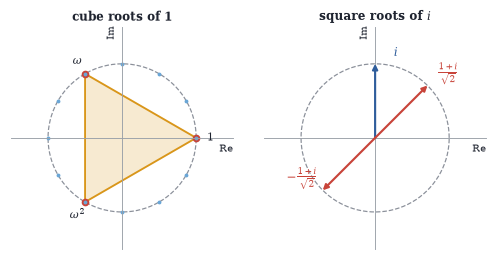

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.25))
ax = complex_plane(axs[0], 1.5, ticks=False); unit_circle(ax)
r = np.exp(2j * np.pi * np.arange(3) / 3)
ax.fill(r.real, r.imag, color=GOLD, alpha=0.2); ax.plot(np.r_[r, r[:1]].real, np.r_[r, r[:1]].imag, color=GOLD)
for k, c in enumerate(r):
    ax.plot(c.real, c.imag, "o", color=RED, ms=4)
    ax.text(1.2 * c.real, 1.2 * c.imag, ["$1$", r"$\omega$", r"$\omega^2$"][k], ha="center", va="center", fontsize=7.5)
r12 = np.exp(2j * np.pi * np.arange(12) / 12)
ax.plot(r12.real, r12.imag, ".", color=SKY, ms=3)
ax.set_title("cube roots of 1")
ax = complex_plane(axs[1], 1.5, ticks=False); unit_circle(ax)
for c, lab in [(1j, "$i$"), (np.exp(1j*np.pi/4), r"$\frac{1+i}{\sqrt{2}}$"), (-np.exp(1j*np.pi/4), r"$-\frac{1+i}{\sqrt{2}}$")]:
    arrow(ax, (c.real, c.imag), color=RED if lab != "$i$" else BLUE, label=lab, offset=(0.28*np.sign(c.real+0.01), 0.15))
ax.set_title("square roots of $i$")

In [14]:
a = np.array([2-3j, 5+4j, -6+7j]); b = np.array([12-5j, 7+22j, -32-9j])
print("ratios b_k / a_k:", b / a)   # a common ratio would mean b is a multiple of a

ratios b_k / a_k: [3.        +2.j         3.        +2.j         1.51764706+3.27058824j]


The four subsets of the previous problem, for $\F=\R$. Only the two sets defined by homogeneous linear equations, (a) and (d), are subspaces: flat and through the origin (black dot).

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


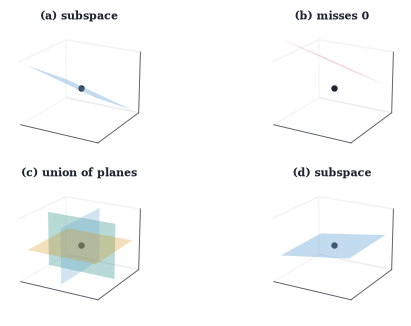

In [15]:
fig = plt.figure(figsize=(W, W * 0.62))
specs = [((1, 2, 3), 0, "(a) subspace"), ((1, 2, 3), 4, "(b) misses 0"), (None, 0, "(c) union of planes"), ((1, 0, -5), 0, "(d) subspace")]
for k, (n, d, title) in enumerate(specs):
    ax = ax3d(fig, pos=221 + k, elev=20, azim=-60, lim=1.6)
    if n is None:
        for nn, col in [((1, 0, 0), SKY), ((0, 1, 0), TEAL), ((0, 0, 1), GOLD)]:
            plane3d(ax, nn, 0, lim=1.4, color=col, alpha=0.3)
    else:
        plane3d(ax, n, d, lim=1.4, color=SKY if d == 0 else ROSE, alpha=0.4)
    ax.scatter([0], [0], [0], color=INK, s=10)
    ax.set_title(title, fontsize=7, pad=-2); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

$\sin x$ and $\sin\sqrt2x$ are each periodic, but their sum (red) is not: it comes close to repeating, as the near-coincidences of its peaks suggest, but never exactly does, because $2\pi$ and $\sqrt2\pi$ have no common multiple.

Text(0.5, 0, '$x$')

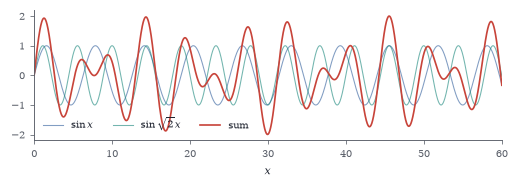

In [16]:
x = np.linspace(0, 60, 3000)
fig, ax = plt.subplots(figsize=(W, 1.6))
ax.plot(x, np.sin(x), color=BLUE, lw=0.7, alpha=0.6, label=r"$\sin x$")
ax.plot(x, np.sin(np.sqrt(2) * x), color=TEAL, lw=0.7, alpha=0.6, label=r"$\sin\sqrt{2}x$")
ax.plot(x, np.sin(x) + np.sin(np.sqrt(2) * x), color=RED, lw=1.1, label="sum")
ax.legend(ncol=3, loc="lower left"); ax.set_xlim(0, 60); ax.set_xlabel("$x$")

Left, over $\R$ the union of three lines through the origin is not closed under addition: the sum of points on two lines leaves all three. Right, over the two-element field the plane has only four points, and it is exactly the union of three lines (each consisting of $0$ and one other point).

Text(0.5, 1.0, 'over $\\{0,1\\}$: three lines fill the plane')

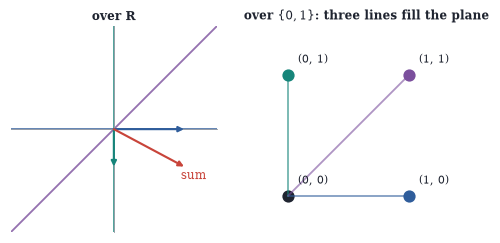

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
ax = plane(axs[0], 2.2, grid=False)
for d, c in [((1, 0), BLUE), ((0, 1), TEAL), ((1, 1), PLUM)]:
    span_line(ax, d, lim=3, color=c, lw=1.2)
arrow(ax, (1.5, 0), color=BLUE); arrow(ax, (0, -0.8), color=TEAL)
arrow(ax, (1.5, -0.8), color=RED, label="sum", offset=(0.2, -0.2))
ax.set_title(r"over $\mathbf{R}$")
ax = axs[1]
pts = {(0, 0): INK, (1, 0): BLUE, (0, 1): TEAL, (1, 1): PLUM}
for p, c in pts.items():
    ax.plot(*p, "o", color=c, ms=7)
    ax.text(p[0] + 0.08, p[1] + 0.1, str(p), fontsize=7)
for p, c in list(pts.items())[1:]:
    ax.plot([0, p[0]], [0, p[1]], color=c, lw=1.2, alpha=0.6)
ax.set_xlim(-0.3, 1.6); ax.set_ylim(-0.3, 1.4); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(r"over $\{0,1\}$: three lines fill the plane")

One subspace $U$ (the horizontal axis), two different complements $V_1$ and $V_2$. The vector $v$ splits as $u+v_1$ and as $u'+v_2$, with different $U$-components. Projection onto $U$ depends on the choice of complement.

Text(0.6000000000000001, -0.22, "$u'$")

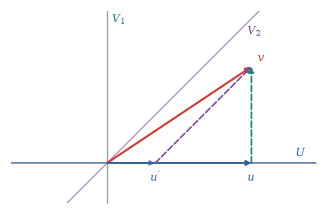

In [18]:
fig, ax = plt.subplots(figsize=(W * 0.62, 2.2))
plane(ax, (-1.2, 2.6, -0.5, 1.9), grid=False)
span_line(ax, (1, 0), lim=3, color=BLUE, lw=1.2); ax.text(2.35, 0.08, "$U$", color=BLUE)
span_line(ax, (0, 1), lim=3, color=TEAL, lw=0.9, alpha=0.6); ax.text(0.06, 1.75, "$V_1$", color=TEAL)
span_line(ax, (1, 1), lim=3, color=PLUM, lw=0.9, alpha=0.6); ax.text(1.75, 1.6, "$V_2$", color=PLUM)
v = np.array([1.8, 1.2])
arrow(ax, v, color=RED, label="$v$", offset=(0.12, 0.1))
arrow(ax, (v[0], 0), color=BLUE, lw=1.1); arrow(ax, (0, v[1]), origin=(v[0], 0), color=TEAL, lw=1.1, ls="--")
arrow(ax, (v[0] - v[1], 0), color=BLUE, lw=1.1, alpha=0.6); arrow(ax, (v[1], v[1]), origin=(v[0] - v[1], 0), color=PLUM, lw=1.1, ls="--")
ax.text(v[0], -0.22, "$u$", color=BLUE, ha="center"); ax.text(v[0] - v[1], -0.22, "$u'$", color=BLUE, ha="center")